lower=112.53209606748737 center=121.10486383916597 upper=129.95084669917827


Parameter R_H in chain BGS1 is not constrained


lower=None center=164.29245288862666 upper=None


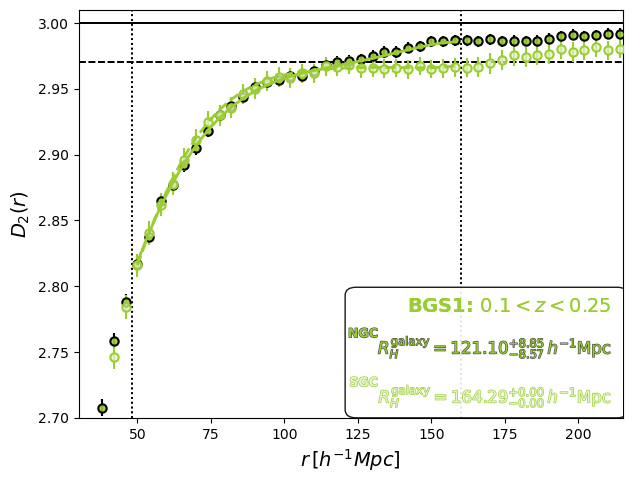

lower=125.18475354638801 center=132.59723898808818 upper=137.13253772872588
lower=96.34020541539155 center=104.42656244149416 upper=119.09262034968498


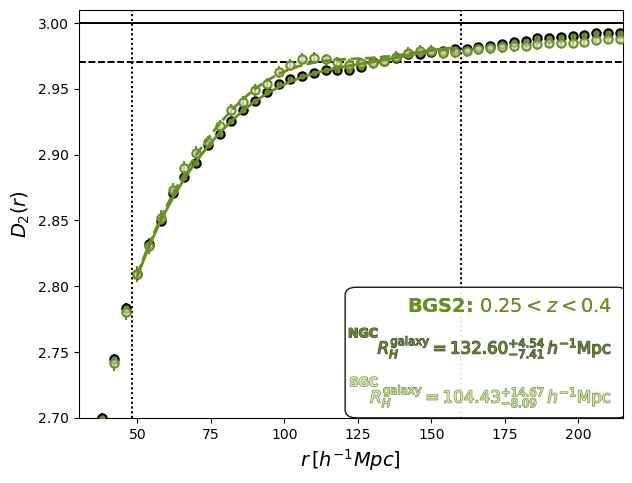

lower=108.63487229079368 center=112.93740799508181 upper=120.3369576072679
lower=108.42611220951677 center=114.10534674577805 upper=120.04462799833584


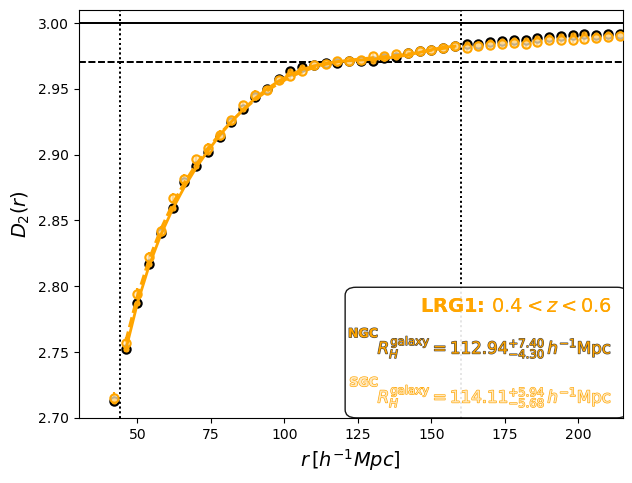

lower=121.2010223760424 center=127.47589242136272 upper=131.3413210250384
lower=117.31908454404197 center=129.34758335962687 upper=133.78060295623152


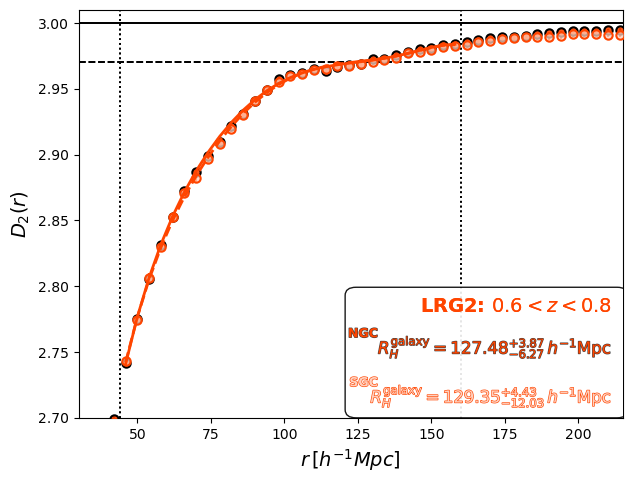

Parameter R_H in chain LRG3 is not constrained


lower=None center=127.24056962159374 upper=None
lower=122.63518230760684 center=127.78085568590735 upper=131.74980530715465


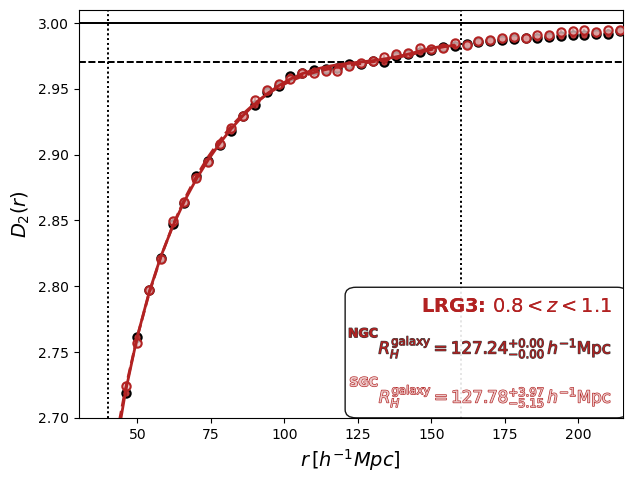

lower=88.5131291832683 center=88.97167932598555 upper=89.48271017173194
lower=86.33396454213397 center=86.76633030176141 upper=87.49754925853098


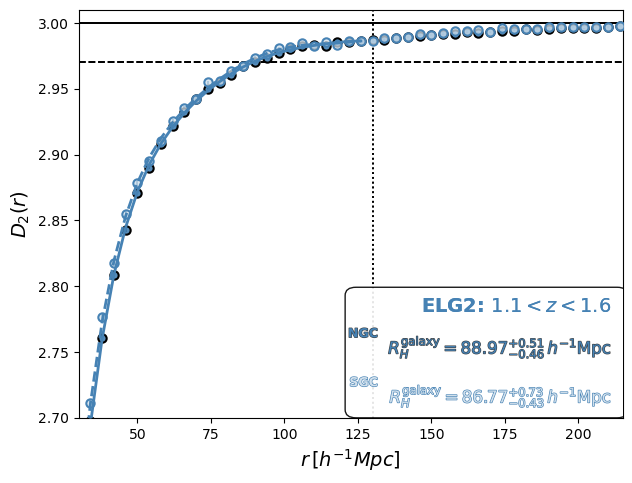

lower=138.58453515018869 center=140.0120142369605 upper=140.91631293091413
lower=141.53640351351703 center=143.04350332091403 upper=144.82964575812426


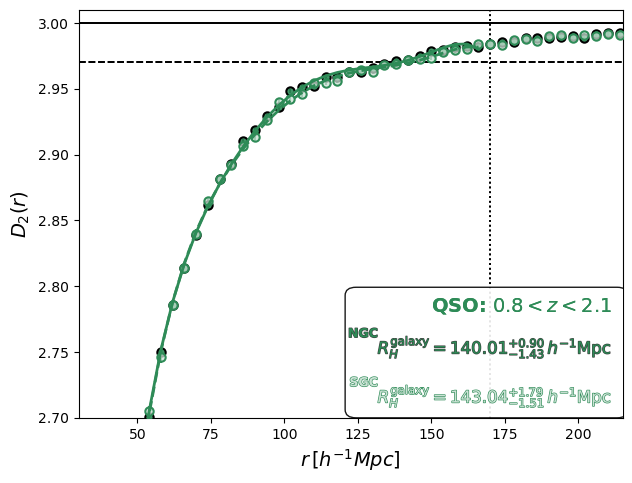

In [9]:
# Compare homogeneity scale fits using different bin widths
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from fit_mock_average_desilike import setup_fitting
from python_routines import get_mocks, run_bestfit, run_emcee, plot_poly_samples, TRACER_COLORS, lighten, get_abacus_dir, run_bestfit_spline
from matplotlib.patches import FancyBboxPatch

if "__main__" in __name__:

    # Parameters from command line
    mock = 5

    tracers, names, colors, templates, templates_real, rmins, rmaxs, model, rebin = setup_fitting()
    model = "poly6"
    #model = "bspline"
    #rmins = {"BGS1": 85.0, "BGS2": 85.0, "LRG1": 85.0, "LRG2": 85.0, "LRG3": 85.0, "ELG2": 65.0, "QSO": 100.0}
    #rmaxs = {"BGS1": 180.0, "BGS2": 180.0, "LRG1": 180.0, "LRG2": 180.0, "LRG3": 180.0, "ELG2": 160.0, "QSO": 195.0}

    # Fit the mock average of each tracer with a 3rd, 4th, 5th, 6th rm order polynomial
    for t, tracer in enumerate(["BGS1", "BGS2", "LRG1", "LRG2", "LRG3", "ELG2", "QSO"]):

        abacus_dir = get_abacus_dir(tracer)
        base = TRACER_COLORS[tracer]
        #SGC_color = lighten(base, 1.2)
        SGC_color=tuple(0.25 * np.array(to_rgb(base)) + 0.75 * np.array([1, 1, 1]))

        # Create ONE figure for this tracer
        fig = plt.figure()
        ax = fig.add_axes((0.13, 0.13, 0.85, 0.85))
        
        
        for skyarea in ["NGC", "SGC"]:
            Abacus, Holi = get_mocks(tracer, skyarea, "weighted", rebin=rebin)

            if skyarea == "NGC":
                marker_face = base
                marker_edge = "black"
                error_color = "black"
                alpha = 0.9
        
            else:
                marker_face = SGC_color
                marker_edge = base
                error_color = base
                alpha = 0.75

            samples = {}
            samples_filename = f"desi/homogeneity/{tracer}/CD_{abacus_dir}_{skyarea}_{mock}_singlecov_{model}_rebin{rebin}_samples_emcee.txt"

            if os.path.isfile(samples_filename):
                samples[model] = pd.read_csv(
                    samples_filename,
                    header=None,
                    sep=r"\s+",
                    names=[f"a_{i}" for i in range(int(model[-1]) + 1)] + ["R_H", "log_post"],)
            else:
        
                coeffs, chi2, polyfit, R_H = run_bestfit(
                    Abacus,
                    model=model,
                    rmin=rmins[tracer],
                    rmax=rmaxs[tracer],
                    datatype="D2",
                    plot=False,
                    single_cov=True,
                    mock=mock)
                print(tracer, skyarea, "Chi2 =", chi2, "R_H =", R_H)
                samples[model] = run_emcee(
                    Abacus,
                    coeffs,
                    model=model,
                    rmin=rmins[tracer],
                    rmax=rmaxs[tracer],
                    datatype="D2",
                    single_cov=True,
                    mock=mock)
                np.savetxt(samples_filename, samples[model].to_numpy(), fmt="%g")
            
            #plot_filename = f"desi/homogeneity/{tracer}/CD_{abacus_dir}_{skyarea}_{mock}_singlecov_{model}_rebin{rebin}.png"
            plot_filename = f"desi/homogeneity/{tracer}/CD_{abacus_dir}_{mock}_singlecov_{model}_rebin{rebin}_NGC_SGC.png"
            
            plot_poly_samples(
                plot_filename,
                tracer,
                color=base if skyarea == "NGC" else SGC_color,
                name=names[t],
                data=Abacus,
                samples=samples[model],
                rmin=rmins[tracer],
                rmax=rmaxs[tracer],
                model=model,
                mock=mock,
                marker_face=marker_face,
                marker_edge=marker_edge,
                ax=ax,
                label=skyarea,
                alpha=alpha
            )

        box = FancyBboxPatch(
            (0.50, 0.01),       # x, y
            0.50,               # width
            0.30,               # height
            transform=ax.transAxes,
            boxstyle="round,pad=0.01,rounding_size=0.02",
            facecolor="white",
            edgecolor="black",
            linewidth=1.0,
            alpha=0.9,
            zorder=4,
        )
        
        ax.add_patch(box)

        
        # Put all text above the box
        for txt in ax.texts:
            txt.set_zorder(5)

            # Save the COMPLETE combined figure
        #fig.savefig(plot_filename, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)


lower=103.1002515541781 center=121.73115644450166 upper=126.31731709131947
lower=105.68081166959519 center=127.92454430193946 upper=141.15093310898447


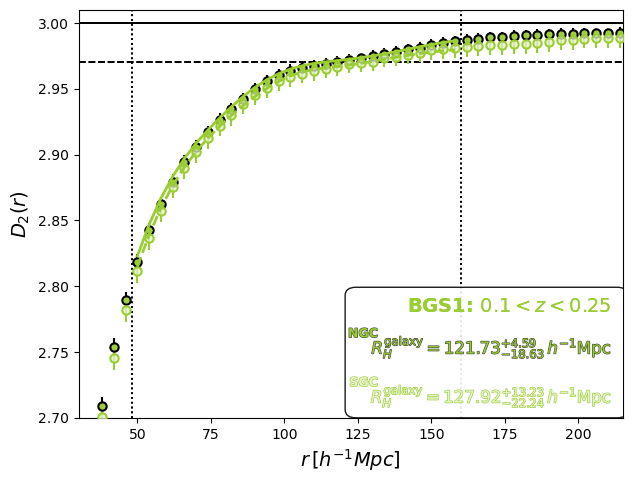

lower=114.01113937164318 center=122.19525824639479 upper=127.57045591941004
lower=112.6982057374473 center=125.5246812514084 upper=135.53215115790553


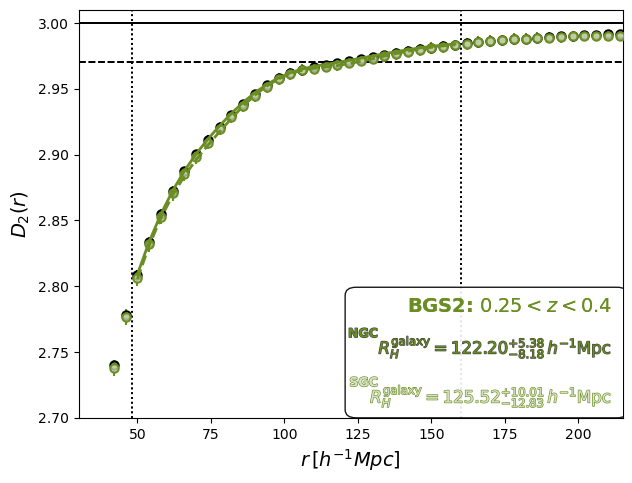

lower=120.91579839829703 center=125.72313634927532 upper=129.87101094922306
lower=118.00057540314711 center=124.8049742076509 upper=129.96256372702214


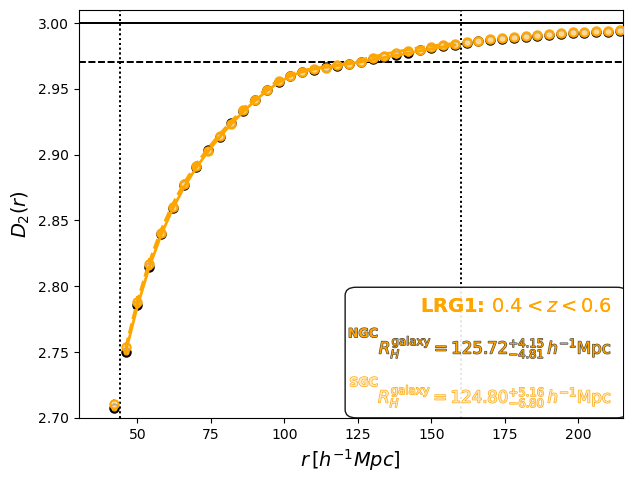

lower=124.22570876784357 center=126.75809790707599 upper=130.55668161592465
lower=121.75137580060948 center=127.11090093303353 upper=132.32511198690702


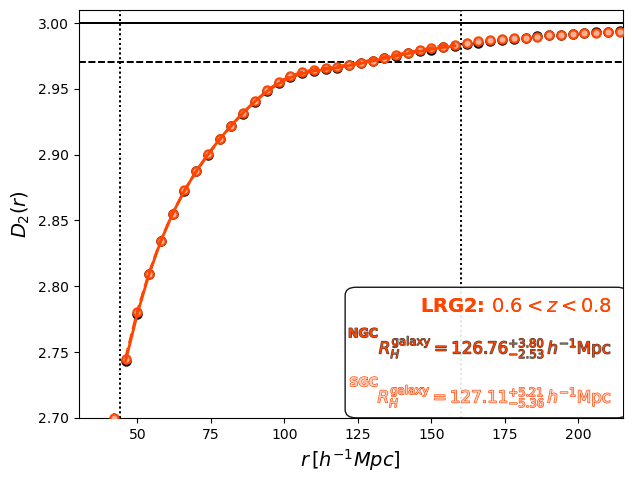

lower=125.54787497809964 center=127.59518746635086 upper=129.6505729533728
lower=125.12782506333565 center=128.40999559039795 upper=131.23882764687156


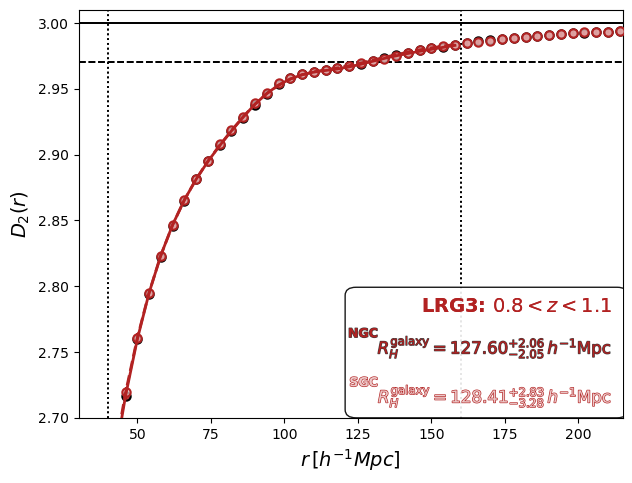

lower=88.70246354138096 center=89.15126864143866 upper=89.67561519398132
lower=87.96549287457005 center=88.53294880442226 upper=89.2506796247887


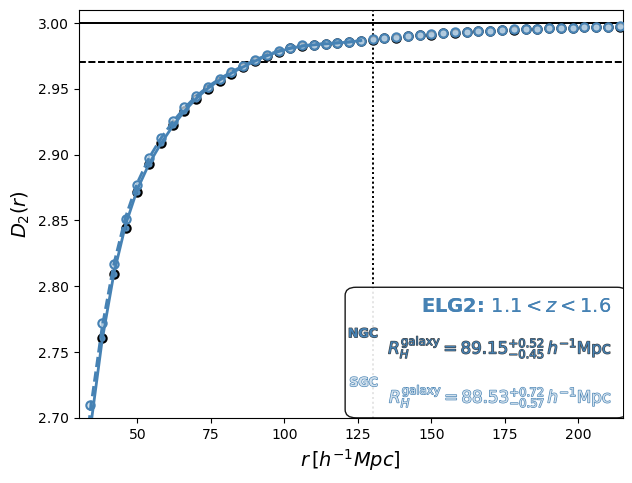

lower=133.20076063018942 center=134.59124924075883 upper=135.65374884351948
lower=133.51210849659375 center=135.1397177514662 upper=136.36808069434207


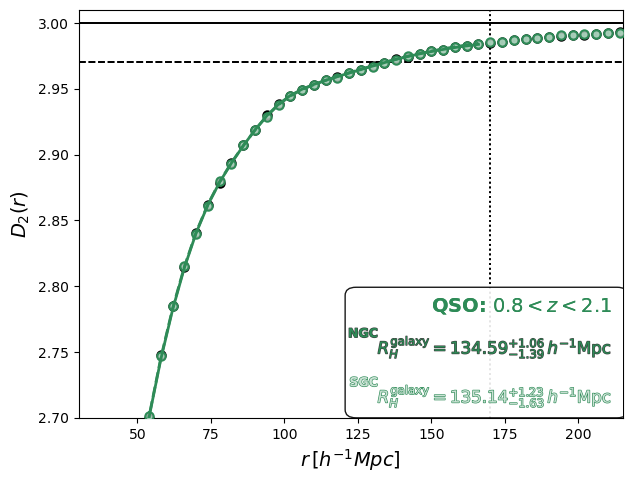

In [16]:
# Compare homogeneity scale fits using different bin widths -- bspline

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from fit_mock_average_desilike import setup_fitting
from python_routines import get_mocks, run_bestfit, run_bestfit_spline, run_emcee, plot_poly_samples, TRACER_COLORS, lighten, get_abacus_dir
from matplotlib.patches import FancyBboxPatch

if "__main__" in __name__:

    # Parameters from command line
    #mock = None

   # for mock in range(1):
    mock=None
    
    tracers, names, colors, templates, templates_real, rmins, rmaxs, model, rebin = setup_fitting()
    #model = "poly6"
    model = "bspline"
    #rmins = {"BGS1": 85.0, "BGS2": 85.0, "LRG1": 85.0, "LRG2": 85.0, "LRG3": 85.0, "ELG2": 65.0, "QSO": 100.0}
    #rmaxs = {"BGS1": 180.0, "BGS2": 180.0, "LRG1": 180.0, "LRG2": 180.0, "LRG3": 180.0, "ELG2": 160.0, "QSO": 195.0}

    # Fit the mock average of each tracer with a 3rd, 4th, 5th, 6th rm order polynomial
    for t, tracer in enumerate(["BGS1", "BGS2", "LRG1", "LRG2", "LRG3", "ELG2", "QSO"]):

        abacus_dir = get_abacus_dir(tracer)
        base = TRACER_COLORS[tracer]
        #SGC_color = lighten(base, 1.2)
        SGC_color=tuple(0.25 * np.array(to_rgb(base)) + 0.75 * np.array([1, 1, 1]))

        # Create ONE figure for this tracer
        fig = plt.figure()
        ax = fig.add_axes((0.13, 0.13, 0.85, 0.85))
        
        
        for skyarea in ["NGC", "SGC"]:
            Abacus, Holi = get_mocks(tracer, skyarea, "weighted", rebin=rebin)

            if skyarea == "NGC":
                marker_face = base
                marker_edge = "black"
                error_color = "black"
                alpha = 0.9
        
            else:
                marker_face = SGC_color
                marker_edge = base
                error_color = base
                alpha = 0.75

            samples = {}
            samples_filename = f"desi/homogeneity/{tracer}/CD_{abacus_dir}_{skyarea}_{mock}_singlecov_{model}_rebin{rebin}_samples_emcee.txt"


            if os.path.isfile(samples_filename):

                samples[model] = pd.read_csv(
                    samples_filename,
                    sep=r"\s+",
                )
            
            else:
            
                # Get the best-fit B-spline
                spline_params, chi2, splinefit, R_H = run_bestfit_spline(
                    Abacus,
                    rmin=rmins[tracer],
                    rmax=rmaxs[tracer],
                    datatype="D2",
                    plot=False,
                    single_cov=True,
                    mock=mock,
                )
            
                print(tracer, skyarea, "Chi2 =", chi2, "R_H =", R_H)
            
                try:
            
                    # Run emcee using the best-fit spline parameters
                    samples[model] = run_emcee(
                        Abacus,
                        spline_params,
                        model="bspline",
                        rmin=rmins[tracer],
                        rmax=rmaxs[tracer],
                        datatype="D2",
                        single_cov=True,
                        mock=mock,
                    )
            
                    # Save INCLUDING column names
                    samples[model].to_csv(
                        samples_filename,
                        sep=" ",
                        index=False,
                    )
            
                except RuntimeError as e:
                    print(f"\nFAILED: {tracer} {skyarea} mock {mock}")
                    print(e)
                    continue
                    
            
            #plot_filename = f"desi/homogeneity/{tracer}/CD_{abacus_dir}_{skyarea}_{mock}_singlecov_{model}_rebin{rebin}.png"
            plot_filename = f"desi/homogeneity/{tracer}/CD_{abacus_dir}_{mock}_singlecov_{model}_rebin{rebin}_NGC_SGC.png"
            
            plot_poly_samples(
                plot_filename,
                tracer,
                color=base if skyarea == "NGC" else SGC_color,
                name=names[t],
                data=Abacus,
                samples=samples[model],
                rmin=rmins[tracer],
                rmax=rmaxs[tracer],
                model=model,
                mock=mock,
                marker_face=marker_face,
                marker_edge=marker_edge,
                ax=ax,
                label=skyarea,
                alpha=alpha
            )

        box = FancyBboxPatch(
            (0.50, 0.01),       # x, y
            0.50,               # width
            0.30,               # height
            transform=ax.transAxes,
            boxstyle="round,pad=0.01,rounding_size=0.02",
            facecolor="white",
            edgecolor="black",
            linewidth=1.0,
            alpha=0.9,
            zorder=4,
        )
        
        ax.add_patch(box)

        
        #Put all text above the box
        for txt in ax.texts:
            txt.set_zorder(5)

            # Save the COMPLETE combined figure
#         fig.savefig(plot_filename, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)



In [5]:
# calculate degrees of freedom for poly6

from fit_mock_average_desilike import setup_fitting
from python_routines import get_mocks, grab_data

tracers, names, colors, templates, templates_real, rmins, rmaxs, model, rebin = setup_fitting()

model = "poly6"

for tracer in tracers:
    Abacus, Holi = get_mocks(tracer, "NGC", "weighted", rebin=rebin)

    data_x, data_y, cov, invcov, corrA, corrB = grab_data(
        Abacus,
        mock=None,
        single_cov=True,
        rmin=rmins[tracer],
        rmax=rmaxs[tracer],
        datatype="D2",
    )

    n_data = len(data_x)
    n_params = int(model[-1]) + 1   # poly6 = 7 coefficients
    dof = n_data - n_params

    print(
        tracer,
        "N_data =", n_data,
        "N_params =", n_params,
        "dof =", dof
    )

BGS1 N_data = 28 N_params = 7 dof = 21
BGS2 N_data = 28 N_params = 7 dof = 21
LRG1 N_data = 29 N_params = 7 dof = 22
LRG2 N_data = 29 N_params = 7 dof = 22
LRG3 N_data = 30 N_params = 7 dof = 23
ELG2 N_data = 25 N_params = 7 dof = 18
QSO N_data = 35 N_params = 7 dof = 28


Parameter R_H in chain BGS1: 0.1 < z < 0.25 15 is not constrained
Parameter R_H in chain BGS1: 0.1 < z < 0.25 16 is not constrained


BGS1 NGC 1.058916338594379 1.085396063832896


Parameter R_H in chain BGS1: 0.1 < z < 0.25 2 is not constrained
Parameter R_H in chain BGS1: 0.1 < z < 0.25 3 is not constrained
Parameter R_H in chain BGS1: 0.1 < z < 0.25 4 is not constrained
Parameter R_H in chain BGS1: 0.1 < z < 0.25 5 is not constrained
Parameter R_H in chain BGS1: 0.1 < z < 0.25 7 is not constrained
Parameter R_H in chain BGS1: 0.1 < z < 0.25 12 is not constrained
Parameter R_H in chain BGS1: 0.1 < z < 0.25 14 is not constrained
Parameter R_H in chain BGS1: 0.1 < z < 0.25 18 is not constrained


BGS1 SGC 0.49414328368071625 0.5374030801080683


Parameter R_H in chain BGS2: 0.25 < z < 0.4 8 is not constrained


...

BGS2 SGC 0.8601008474463392 1.042836253204983
LRG1 NGC 1.1382219126540847 1.0892805976446756


Parameter R_H in chain LRG1: 0.4 < z < 0.6 20 is not constrained


LRG1 SGC 1.2684803434535117 1.2134236708229296
LRG2 NGC 1.3506947565539373 1.2533758292548245


Parameter R_H in chain LRG2: 0.6 < z < 0.8 0 is not constrained
Parameter R_H in chain LRG2: 0.6 < z < 0.8 12 is not constrained


LRG2 SGC 1.1501900376536327 1.1080993320807795
LRG3 NGC 1.058035222502429 1.0130260376365212
LRG3 SGC 1.3827220703408636 1.2962927347839848
ELG2 NGC 0.9834917961652017 0.9750327048061933
ELG2 SGC 1.1554955219256693 1.1504383482004854
QSO NGC 0.9517264030343296 0.9670892501688518
QSO SGC 0.954494971455297 0.9363927339189058


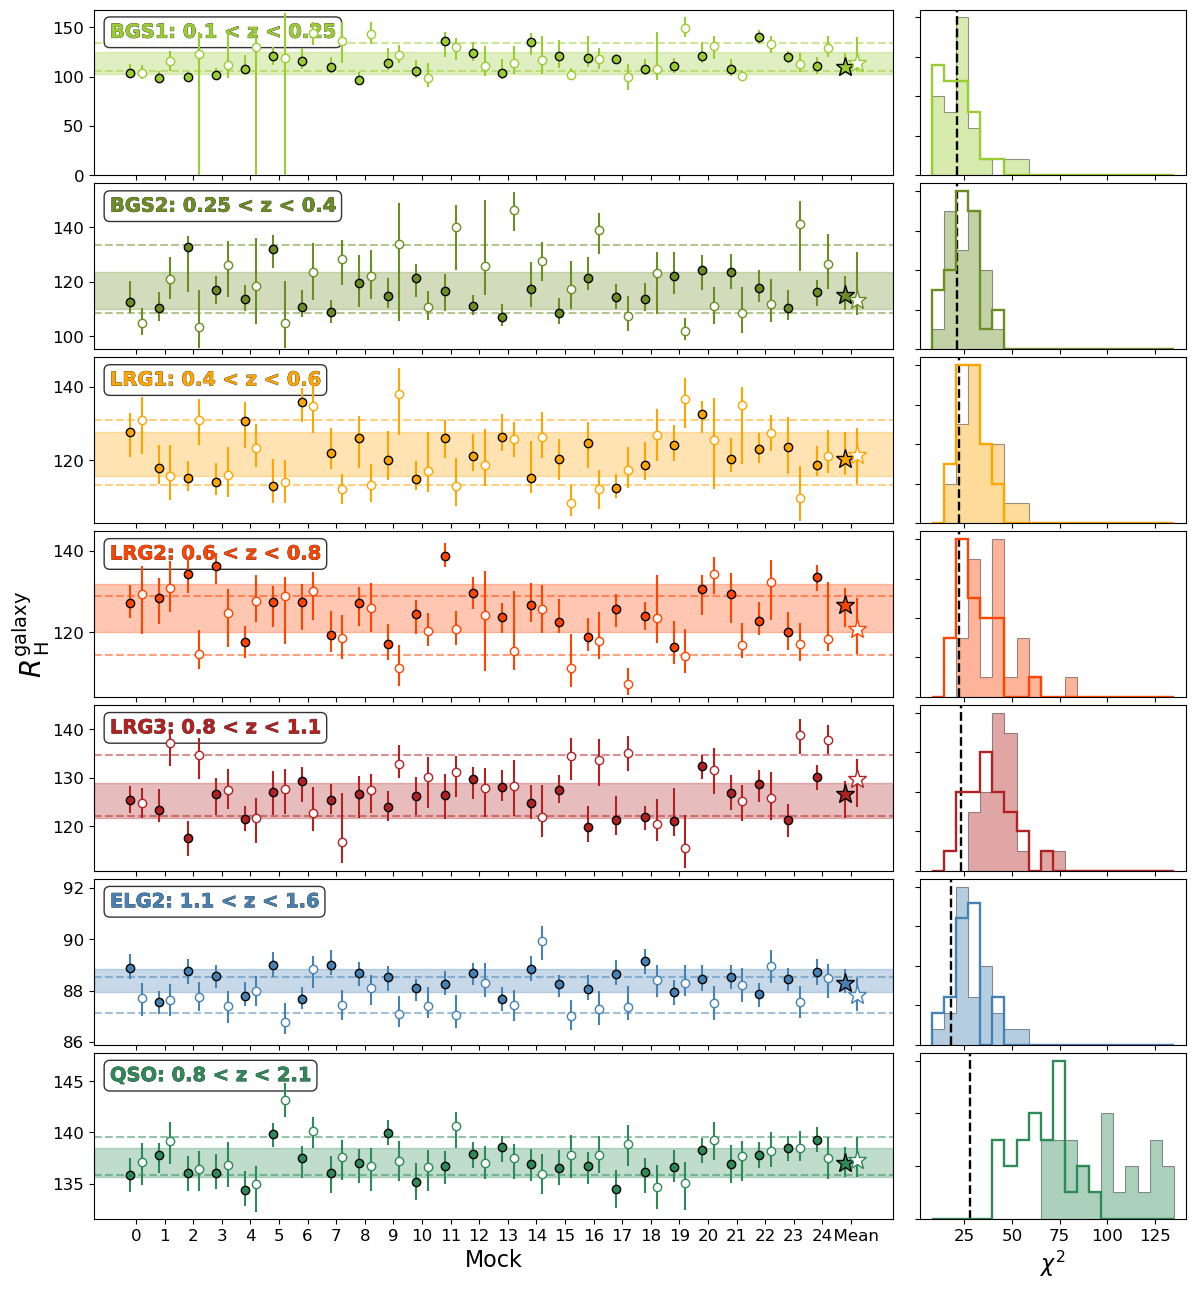

In [1]:
# Compare homogeneity scale fits using different bin widths -- poly6
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from desilike import setup_logging
from desilike.samples import Chain
from chainconsumer import ChainConsumer, Chain as cChain
from fit_mock_average_desilike import setup_fitting
from python_routines import get_abacus_dir
import matplotlib.patheffects as path_effects


if "__main__" in __name__:

    tracers, names, colors, templates, templates_real, rmin, rmaxs, model, rebin = setup_fitting()
    model = "poly6"

    dof = np.array([21, 21, 22, 22, 23, 18, 28])

    # Separate NGC and SGC
    # Create figure with custom width ratios (3:1)
    fig = plt.figure(figsize=(12, 13))
    gs = fig.add_gridspec(
        len(tracers), 2, width_ratios=[3, 1], hspace=0.05, wspace=0.05, left=0.07, right=0.98, top=0.98, bottom=0.05
    )
    # Accumulate all the measurements
    left_axes, right_axes = [], []
    chi2_values, std_values = [], []
    for t, tracer in enumerate(tracers):

        abacus_dir = get_abacus_dir(tracer)

        Rhmin, Rhmax = 1.0e10, -1.0e10
        for s, skyarea in enumerate(["NGC", "SGC"]):

            # Left panels (error bar plots)
            if skyarea == "NGC":
                ax_left = fig.add_subplot(gs[t, 0])
                left_axes.append(ax_left)
            else:
                ax_left = left_axes[t]

            c = ChainConsumer()
            for mc in range(25):
            #for mc in [None]:
                file = f"desi/homogeneity/{tracer}/CD_{abacus_dir}_{skyarea}_{mc}_singlecov_{model}_rebin{rebin}_samples_emcee.txt"
                samples = pd.read_csv(file, header=None, sep=r"\s+", names=[f"a_{i}" for i in range(int(model[-1]) + 1)] + ["R_H", "log_post"],)
                chi2_values.append(
                    -2.0
                    * np.asarray(samples["log_post"]).max()
                )
                std_values.append(np.std(samples["R_H"]))

                c.add_chain(
                    cChain(
                        samples=samples,
                        name=names[t] + f" {mc}",
                        linewidth=1.0,
                        bins=10 if tracer == "LRG" else 20,
                    )
                )

            file = f"desi/homogeneity/{tracer}/CD_{abacus_dir}_{skyarea}_None_singlecov_{model}_rebin{rebin}_samples_emcee.txt"
            samples = pd.read_csv( file, header=None, sep=r"\s+", names=[f"a_{i}" for i in range(int(model[-1]) + 1)] + ["R_H", "log_post"],)
            samples[r"$\chi^{2}$"] = -2.0 * np.asarray(
                samples["log_post"])
            

            c.add_chain(
                cChain(
                    samples=samples,
                    name=names[t] + " Mean",
                    linewidth=1.7,
                    bins=10 if tracer == "LRG" else 20,
                )
            )

            # Return R_H error bounds using ChainConsumer
            results = c.analysis.get_summary()
            Rhs = []
            for n in c._chains:
                if results[n]["R_H"].lower is not None:
                    Rhs.append(results[n]["R_H"].array)
                else:
                    Rhs.append(np.quantile(c._chains[n].samples["R_H"], [0.16, 0.5, 0.84]))
            Rhs = np.array(Rhs)

            Rhmin = np.amin([Rhmin, 0.995 * np.nanmin(Rhs[:, 0])])
            Rhmax = np.amax([Rhmax, 1.020 * np.nanmax(Rhs[:, 2])])

            # Plot error bars
            ax_left.errorbar(
                np.arange(0, 25) - (0.2 if skyarea == "NGC" else -0.2),
                Rhs[:-1, 1],
                yerr=[Rhs[:-1, 1] - Rhs[:-1, 0], Rhs[:-1, 2] - Rhs[:-1, 1]],
                marker="o",
                ls="None",
                color=colors[tracer],
                mfc=colors[tracer] if skyarea == "NGC" else "w",
                mec="k" if skyarea == "NGC" else colors[tracer],
                alpha=1.0,
                zorder=5,
            )
            ax_left.errorbar(
                [25 - (0.2 if skyarea == "NGC" else -0.2)],
                [Rhs[-1, 1]],
                yerr=[[Rhs[-1, 1] - Rhs[-1, 0]], [Rhs[-1, 2] - Rhs[-1, 1]]],
                marker="*",
                ms=14,
                ls="None",
                color=colors[tracer],
                mfc=colors[tracer] if skyarea == "NGC" else "w",
                mec="k" if skyarea == "NGC" else colors[tracer],
                alpha=1.0,
                zorder=5,
            )

            # Add horizontal fill
            Rh_mean, Rh_std = np.mean(Rhs[:-1, 1]), np.std(Rhs[:-1, 1])
            # ax_left.axhline(y=Rh_mean, alpha=0.5, color=colors[tracer], zorder=1, ls="-" if skyarea == "NGC" else "--")
            if skyarea == "NGC":
                ax_left.axhspan(Rh_mean - Rh_std, Rh_mean + Rh_std, alpha=0.3, color=colors[tracer], zorder=0)
            else:
                ax_left.axhline(y=Rh_mean - Rh_std, alpha=0.5, color=colors[tracer], zorder=1, ls="--")
                ax_left.axhline(y=Rh_mean + Rh_std, alpha=0.5, color=colors[tracer], zorder=1, ls="--")

            # First is ratio of std(mean(RH_mock_i)) to <std(RH_mock_i)>
            # Second is ratio of std(mean(RH_mock_i)) to std(RH_mock_mean)
            print(
                tracer,
                skyarea,
                1.0 / (np.array(std_values[(2 * t + s) * 25 : (2 * t + s + 1) * 25]).mean() / Rh_std),
                1.0 / (np.std(samples["R_H"]) / Rh_std),
            )

        # Add text label in top-left
        text = ax_left.text(
            0.02,
            0.92,
            names[t],
            transform=ax_left.transAxes,
            verticalalignment="top",
            fontsize=14,
            fontweight="bold",
            color=colors[tracer],
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
        )
        text.set_path_effects(
            [path_effects.Stroke(linewidth=0.5, foreground="black", alpha=0.8), path_effects.Normal()]
        )

        # Format axes
        ax_left.set_xticks(np.arange(0, 26))
        ax_left.set_ylim((Rhmin, Rhmax))
        ax_left.set_xticklabels([str(x) for x in np.arange(0, 25)] + ["  Mean"], fontsize=12, rotation=0)
        if t < 5:
            ax_left.set_xticklabels([])
        else:
            ax_left.set_xlabel("Mock", fontsize=16)
        ax_left.tick_params(axis="y", labelsize=12)

    all_chi2 = np.array(chi2_values).reshape(len(tracers), 50)
    n_bins = 20
    common_bins = np.linspace(all_chi2.min(), all_chi2.max(), n_bins + 1)

    # Plot histograms
    for t, tracer in enumerate(tracers):
        for s, skyarea in enumerate(["NGC", "SGC"]):
            if skyarea == "NGC":
                if t == 0:
                    ax_right = fig.add_subplot(gs[t, 1])
                else:
                    ax_right = fig.add_subplot(gs[t, 1], sharex=right_axes[0])
                right_axes.append(ax_right)
            else:
                ax_right = right_axes[t]

            ax_right.hist(
                all_chi2[t, s * 25 : (s + 1) * 25],
                bins=common_bins,
                orientation="vertical",
                color=colors[tracer],
                alpha=0.4 if skyarea == "NGC" else 1.0,
                lw=0.8 if skyarea == "NGC" else 1.7,
                edgecolor="black" if skyarea == "NGC" else colors[tracer],
                histtype="stepfilled" if skyarea == "NGC" else "step",
            )

            if skyarea == "NGC":
                ax_right.axvline(x=dof[t], color="k", ls="--", lw=1.7)

                if t < 5:
                    ax_right.tick_params(axis="x", labelbottom=False)
                else:
                    ax_right.set_xlabel(r"$\chi^2$", fontsize=16)
                    ax_right.tick_params(axis="x", labelsize=12)

                ax_right.set_yticklabels([])

    # Add shared y-axis label for left panels
    fig.text(0.0, 0.5, r"$R^{\mathrm{galaxy}}_{\,\mathrm{H}}$", va="center", rotation="vertical", fontsize=20)

    plt.show()


In [19]:
# calculate degrees of freedom for bspline

from fit_mock_average_desilike import setup_fitting
from python_routines import get_mocks, grab_data

tracers, names, colors, templates, templates_real, rmins, rmaxs, model, rebin = setup_fitting()

model = "bspline"

for tracer in tracers:
    Abacus, Holi = get_mocks(tracer, "NGC", "weighted", rebin=rebin)

    data_x, data_y, cov, invcov, corrA, corrB = grab_data(
        Abacus,
        mock=None,
        single_cov=True,
        rmin=rmins[tracer],
        rmax=rmaxs[tracer],
        datatype="D2",
    )

    n_data = len(data_x)

    # Match the B-spline construction in run_bestfit_spline()
    n_params = n_data // 3

    dof = n_data - n_params

    print(
        tracer,
        "N_data =", n_data,
        "N_params =", n_params,
        "dof =", dof
    )

BGS1 N_data = 28 N_params = 9 dof = 19
BGS2 N_data = 28 N_params = 9 dof = 19
LRG1 N_data = 29 N_params = 9 dof = 20
LRG2 N_data = 29 N_params = 9 dof = 20
LRG3 N_data = 30 N_params = 10 dof = 20
ELG2 N_data = 25 N_params = 8 dof = 17
QSO N_data = 35 N_params = 11 dof = 24


BGS1 NGC 1.010676839361149 1.0124094599195357
BGS1 SGC 0.4894738844184006 0.530862403278481
BGS2 NGC 1.000319698842887 0.9317775696716651
BGS2 SGC 0.8599753456225331 1.021801047986452
LRG1 NGC 0.8830459503467373 0.8878101952273884
LRG1 SGC 0.9409356582150838 0.9349964320168336
LRG2 NGC 1.0991079985625556 1.1500767104262897
LRG2 SGC 1.051949149876336 1.0483380172498622
LRG3 NGC 0.8470173676701483 0.8683318686111852
LRG3 SGC 1.0555133154667315 1.1127394154007448
ELG2 NGC 1.2081784581326573 1.1931124325384903
ELG2 SGC 1.0069901878033347 1.0162893267704596
QSO NGC 1.1452318867531994 1.1571278000395007
QSO SGC 1.0367792872400627 1.0697132189280152


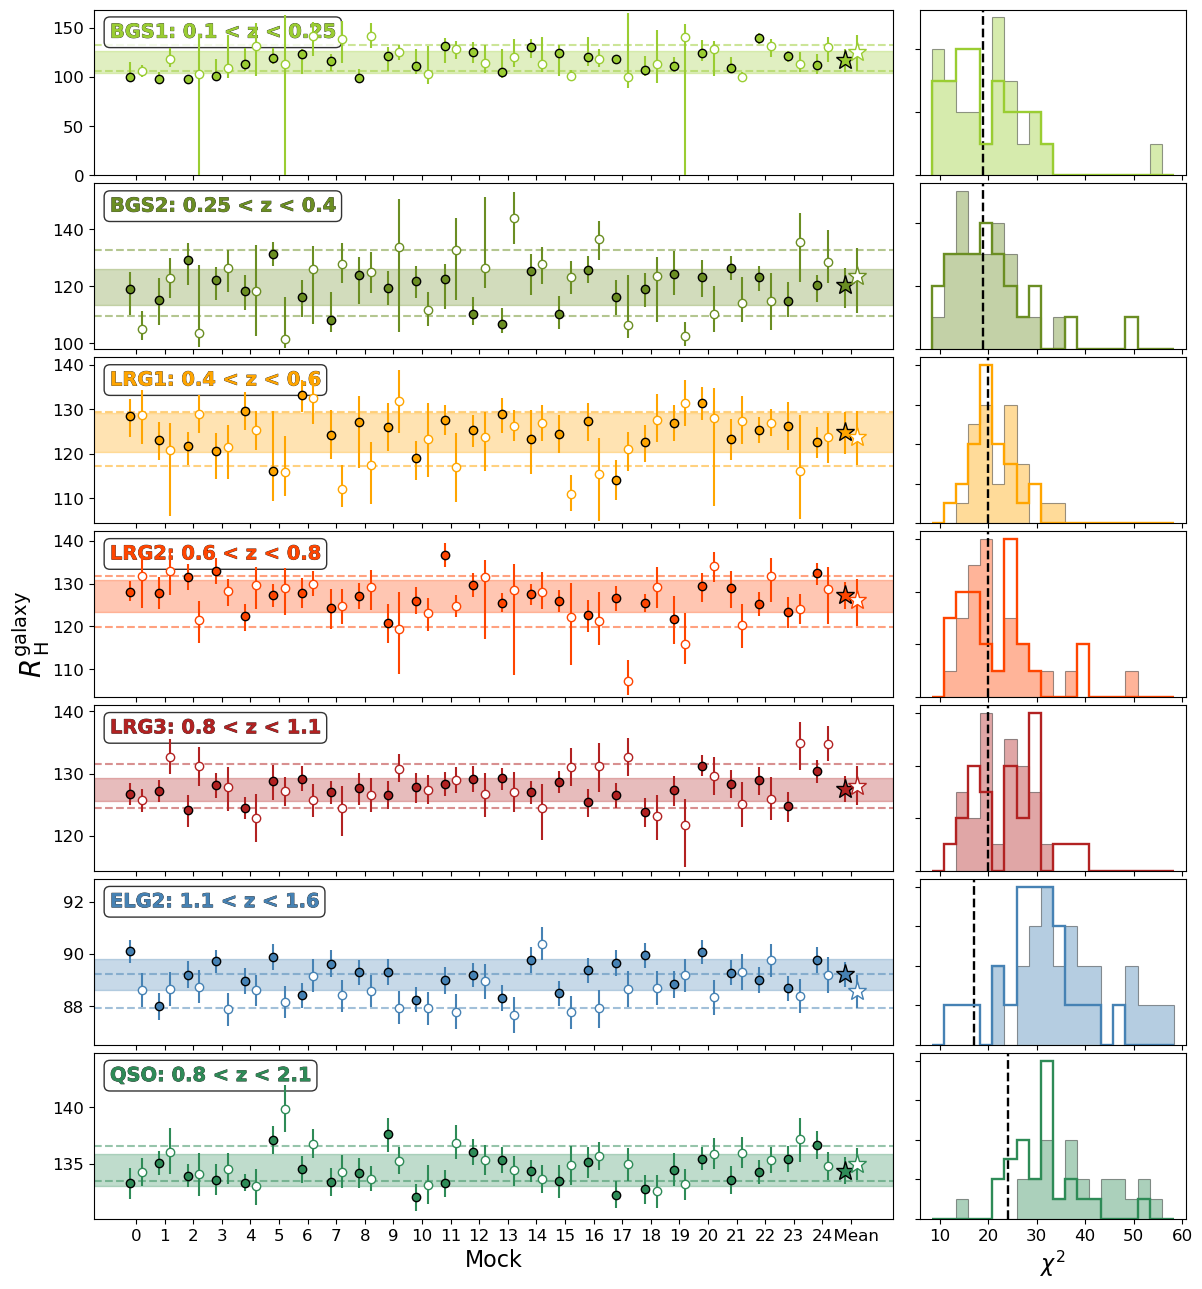

In [20]:
# Compare homogeneity scale fits using different bin widths --- bspline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from desilike import setup_logging
from desilike.samples import Chain
from chainconsumer import ChainConsumer, Chain as cChain
from fit_mock_average_desilike import setup_fitting
from python_routines import get_abacus_dir
import matplotlib.patheffects as path_effects


if "__main__" in __name__:

    tracers, names, colors, templates, templates_real, rmin, rmaxs, model, rebin = setup_fitting()
    model = "bspline"

    dof = np.array([19, 19, 20, 20, 20, 17, 24])

    # Separate NGC and SGC
    # Create figure with custom width ratios (3:1)
    fig = plt.figure(figsize=(12, 13))
    gs = fig.add_gridspec(
        len(tracers), 2, width_ratios=[3, 1], hspace=0.05, wspace=0.05, left=0.07, right=0.98, top=0.98, bottom=0.05
    )
    # Accumulate all the measurements
    left_axes, right_axes = [], []
    chi2_values, std_values = [], []
    for t, tracer in enumerate(tracers):

        abacus_dir = get_abacus_dir(tracer)

        Rhmin, Rhmax = 1.0e10, -1.0e10
        for s, skyarea in enumerate(["NGC", "SGC"]):

            # Left panels (error bar plots)
            if skyarea == "NGC":
                ax_left = fig.add_subplot(gs[t, 0])
                left_axes.append(ax_left)
            else:
                ax_left = left_axes[t]

            c = ChainConsumer()
            for mc in range(25):
            #for mc in [None]:
                file = f"desi/homogeneity/{tracer}/CD_{abacus_dir}_{skyarea}_{mc}_singlecov_{model}_rebin{rebin}_samples_emcee.txt"
                #samples = pd.read_csv(file, header=None, sep=r"\s+", names=[f"a_{i}" for i in range(int(model[-1]) + 1)] + ["R_H", "log_post"],)

                samples = pd.read_csv(file, sep=r"\s+",)
                
                chi2_values.append(
                    -2.0
                    * np.asarray(samples["log_post"]).max()
                )
                std_values.append(np.std(samples["R_H"]))

                c.add_chain(
                    cChain(
                        samples=samples,
                        name=names[t] + f" {mc}",
                        linewidth=1.0,
                        bins=10 if tracer == "LRG" else 20,
                    )
                )

            file = f"desi/homogeneity/{tracer}/CD_{abacus_dir}_{skyarea}_None_singlecov_{model}_rebin{rebin}_samples_emcee.txt"
            #samples = pd.read_csv( file, header=None, sep=r"\s+", names=[f"a_{i}" for i in range(int(model[-1]) + 1)] + ["R_H", "log_post"],)

            samples = pd.read_csv(file, sep=r"\s+",)
            
            samples[r"$\chi^{2}$"] = -2.0 * np.asarray(
                samples["log_post"])
            

            c.add_chain(
                cChain(
                    samples=samples,
                    name=names[t] + " Mean",
                    linewidth=1.7,
                    bins=10 if tracer == "LRG" else 20,
                )
            )

            # Return R_H error bounds using ChainConsumer
            #results = c.analysis.get_summary()
            Rhs = []
            #for n in c._chains:
            #    if results[n]["R_H"].lower is not None:
            #        Rhs.append(results[n]["R_H"].array)
            #    else:
            #        Rhs.append(np.quantile(c._chains[n].samples["R_H"], [0.16, 0.5, 0.84]))

            for n in c._chains: #changed for bspline files
                rh = np.asarray(c._chains[n].samples["R_H"])
                rh = rh[np.isfinite(rh)]
                Rhs.append(np.quantile(rh, [0.16, 0.5, 0.84]))

            Rhs = np.array(Rhs)

            Rhmin = np.amin([Rhmin, 0.995 * np.nanmin(Rhs[:, 0])])
            Rhmax = np.amax([Rhmax, 1.020 * np.nanmax(Rhs[:, 2])])

            # Plot error bars
            ax_left.errorbar(
                np.arange(0, 25) - (0.2 if skyarea == "NGC" else -0.2),
                Rhs[:-1, 1],
                yerr=[Rhs[:-1, 1] - Rhs[:-1, 0], Rhs[:-1, 2] - Rhs[:-1, 1]],
                marker="o",
                ls="None",
                color=colors[tracer],
                mfc=colors[tracer] if skyarea == "NGC" else "w",
                mec="k" if skyarea == "NGC" else colors[tracer],
                alpha=1.0,
                zorder=5,
            )
            ax_left.errorbar(
                [25 - (0.2 if skyarea == "NGC" else -0.2)],
                [Rhs[-1, 1]],
                yerr=[[Rhs[-1, 1] - Rhs[-1, 0]], [Rhs[-1, 2] - Rhs[-1, 1]]],
                marker="*",
                ms=14,
                ls="None",
                color=colors[tracer],
                mfc=colors[tracer] if skyarea == "NGC" else "w",
                mec="k" if skyarea == "NGC" else colors[tracer],
                alpha=1.0,
                zorder=5,
            )

            # Add horizontal fill
            Rh_mean, Rh_std = np.mean(Rhs[:-1, 1]), np.std(Rhs[:-1, 1])
            # ax_left.axhline(y=Rh_mean, alpha=0.5, color=colors[tracer], zorder=1, ls="-" if skyarea == "NGC" else "--")
            if skyarea == "NGC":
                ax_left.axhspan(Rh_mean - Rh_std, Rh_mean + Rh_std, alpha=0.3, color=colors[tracer], zorder=0)
            else:
                ax_left.axhline(y=Rh_mean - Rh_std, alpha=0.5, color=colors[tracer], zorder=1, ls="--")
                ax_left.axhline(y=Rh_mean + Rh_std, alpha=0.5, color=colors[tracer], zorder=1, ls="--")

            # First is ratio of std(mean(RH_mock_i)) to <std(RH_mock_i)>
            # Second is ratio of std(mean(RH_mock_i)) to std(RH_mock_mean)
            print(
                tracer,
                skyarea,
                1.0 / (np.array(std_values[(2 * t + s) * 25 : (2 * t + s + 1) * 25]).mean() / Rh_std),
                1.0 / (np.std(samples["R_H"]) / Rh_std),
            )

        # Add text label in top-left
        text = ax_left.text(
            0.02,
            0.92,
            names[t],
            transform=ax_left.transAxes,
            verticalalignment="top",
            fontsize=14,
            fontweight="bold",
            color=colors[tracer],
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
        )
        text.set_path_effects(
            [path_effects.Stroke(linewidth=0.5, foreground="black", alpha=0.8), path_effects.Normal()]
        )

        # Format axes
        ax_left.set_xticks(np.arange(0, 26))
        ax_left.set_ylim((Rhmin, Rhmax))
        ax_left.set_xticklabels([str(x) for x in np.arange(0, 25)] + ["  Mean"], fontsize=12, rotation=0)
        if t < 5:
            ax_left.set_xticklabels([])
        else:
            ax_left.set_xlabel("Mock", fontsize=16)
        ax_left.tick_params(axis="y", labelsize=12)

    all_chi2 = np.array(chi2_values).reshape(len(tracers), 50)
    n_bins = 20
    common_bins = np.linspace(all_chi2.min(), all_chi2.max(), n_bins + 1)

    # Plot histograms
    for t, tracer in enumerate(tracers):
        for s, skyarea in enumerate(["NGC", "SGC"]):
            if skyarea == "NGC":
                if t == 0:
                    ax_right = fig.add_subplot(gs[t, 1])
                else:
                    ax_right = fig.add_subplot(gs[t, 1], sharex=right_axes[0])
                right_axes.append(ax_right)
            else:
                ax_right = right_axes[t]

            ax_right.hist(
                all_chi2[t, s * 25 : (s + 1) * 25],
                bins=common_bins,
                orientation="vertical",
                color=colors[tracer],
                alpha=0.4 if skyarea == "NGC" else 1.0,
                lw=0.8 if skyarea == "NGC" else 1.7,
                edgecolor="black" if skyarea == "NGC" else colors[tracer],
                histtype="stepfilled" if skyarea == "NGC" else "step",
            )

            if skyarea == "NGC":
                ax_right.axvline(x=dof[t], color="k", ls="--", lw=1.7)

                if t < len(tracers) - 1 :
                    ax_right.tick_params(axis="x", labelbottom=False)
                else:
                    ax_right.set_xlabel(r"$\chi^2$", fontsize=16)
                    ax_right.tick_params(axis="x", labelsize=12)

                ax_right.set_yticklabels([])

    # Add shared y-axis label for left panels
    fig.text(0.0, 0.5, r"$R^{\mathrm{galaxy}}_{\,\mathrm{H}}$", va="center", rotation="vertical", fontsize=20)

    plt.show()


In [2]:
# check for missing runs

import os
from fit_mock_average_desilike import setup_fitting
from python_routines import get_abacus_dir

tracers, names, colors, templates, templates_real, rmins, rmaxs, model, rebin = setup_fitting()
model = "bspline"

failed = []

for mock in range(25):
    for tracer in ["BGS1", "BGS2", "LRG1", "LRG2", "LRG3", "ELG2", "QSO"]:
        abacus_dir = get_abacus_dir(tracer)

        for skyarea in ["NGC", "SGC"]:
            filename = (
                f"desi/homogeneity/{tracer}/"
                f"CD_{abacus_dir}_{skyarea}_{mock}_singlecov_"
                f"{model}_rebin{rebin}_samples_emcee.txt"
            )

            if not os.path.isfile(filename):
                failed.append((mock, tracer, skyarea))

print("Failed / missing runs:")
for mock, tracer, skyarea in failed:
    print(f"mock {mock}: {tracer} {skyarea}")

print(f"\nTotal missing: {len(failed)}")

Failed / missing runs:

Total missing: 0
